# SmokeCheck

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/DenisLazerko/smokecheck/blob/main/smokecheck.ipynb)

Next-day wildfire smoke warnings for high school sports in Washington, Oregon, Idaho and Montana.

Each evening, SmokeCheck predicts tomorrow's average PM2.5 for a city. If the forecast is high enough, it says to move tomorrow's practice indoors. We compare it with two other ways of deciding: "tomorrow = today" and the official CAMS air quality forecast.

The notebook runs top to bottom in about a minute. It loads one small CSV file that `build_dataset.py` made from EPA and Open-Meteo data.

## 0. Setup

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

SMOKE = 35.0          # µg/m³ daily mean: where "unhealthy for sensitive groups" starts
MISS_COST = 3         # one missed warning counts as much as three false alarms
TRAIN_YEARS = range(2013, 2022)
TUNE_YEAR = 2022
TEST_YEARS = [2023, 2024, 2025]

# Load the data from the repo folder if it is here, otherwise from GitHub.
REPO = "grushet/smokecheck"   # GitHub user/repo that holds the data folder
BASE = "data/" if os.path.exists("data/pnw_smoke_days.csv") else \
    f"https://raw.githubusercontent.com/{REPO}/main/data/"
raw = pd.read_csv(BASE + "pnw_smoke_days.csv", parse_dates=["date"])
cities = pd.read_csv(BASE + "cities.csv")
os.makedirs("figures", exist_ok=True)
print(f"{len(raw):,} city-days, {raw.city.nunique()} cities, "
      f"{raw.date.dt.year.min()}-{raw.date.dt.year.max()}")
raw.head()

34,840 city-days, 20 cities, 2013-2025


,city,date,pm25,n_monitors,wind_max,wind_dir,precip,temp_max,rh,fc_wind_max,fc_precip,fc_temp_max,fc_rh,fc_wind_dir,cams_pm25
0,Bellingham,2013-06-20,1.84,1,18.3,203,20.1,12.9,96,NaN,NaN,NaN,NaN,NaN,NaN
1,Bellingham,2013-06-21,1.93,1,11.3,188,0.5,16.2,85,NaN,NaN,NaN,NaN,NaN,NaN
2,Bellingham,2013-06-22,4.33,1,8.8,268,0.0,21.0,78,NaN,NaN,NaN,NaN,NaN,NaN
3,Bellingham,2013-06-23,7.04,1,6.9,2,2.7,21.7,85,NaN,NaN,NaN,NaN,NaN,NaN
4,Bellingham,2013-06-24,2.72,1,17.7,160,14.2,16.3,94,NaN,NaN,NaN,NaN,NaN,NaN


## 1. The data

One row per city per day, July to October, 2013-2025. `pm25` is the median of the city's EPA monitors that day. Weather is what actually happened (ERA5). Columns starting with `fc_` are weather forecasts issued the day before, which only exist for 2024-2025. `cams_pm25` is the official CAMS forecast, archived from August 2022 on.

Some Oregon monitors only took a sample every third day before 2023. Those cities show about 40 days a season in the table below. With no back-to-back days, they can't be used for training, so they become a test of cities the model has never seen.

In [2]:
season = raw[raw.date.dt.month.between(7, 10)]
smoke_days = (season.assign(year=season.date.dt.year, smoke=season.pm25 > SMOKE)
              .pivot_table(index="city", columns="year", values="smoke", aggfunc="sum")
              .astype(int))
measured = (season.assign(year=season.date.dt.year)
            .pivot_table(index="city", columns="year", values="pm25", aggfunc="count"))
print("Days with a measurement, Jul 1 - Oct 31 (out of 123):")
display(measured.fillna(0).astype(int))
print(f"Smoke days (daily mean > {SMOKE:.0f} µg/m³):")
display(smoke_days)

Days with a measurement, Jul 1 - Oct 31 (out of 123):


year,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
city,,,,,,,,,,,,,
Bellingham,97,120,119,123,123,123,123,123,93,123,123,123,123
Bend,0,0,0,0,0,0,0,0,0,0,31,118,123
Boise,0,0,40,41,41,41,45,116,98,119,122,123,116
Bozeman,0,0,80,119,123,122,123,121,109,101,123,123,106
Bremerton,123,123,123,122,123,110,123,120,120,123,123,123,122
Butte,120,118,112,123,120,123,123,123,123,120,122,123,123
Ellensburg,0,0,106,89,119,123,123,119,121,123,123,120,123
Eugene,47,43,43,48,46,47,41,123,123,123,123,123,123
Grants Pass,21,20,19,20,19,17,18,12,21,40,120,123,119


Smoke days (daily mean > 35 µg/m³):


year,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
city,,,,,,,,,,,,,
Bellingham,0,0,0,0,4,5,0,9,1,6,0,0,0
Bend,0,0,0,0,0,0,0,0,0,0,0,15,3
Boise,0,0,1,0,3,1,0,15,6,5,0,13,0
Bozeman,0,0,2,12,1,3,0,7,7,1,0,0,0
Bremerton,0,0,0,0,5,5,0,9,1,3,1,0,0
Butte,0,1,9,0,20,1,0,8,20,9,0,5,0
Ellensburg,0,0,1,0,13,11,0,10,5,1,3,0,3
Eugene,0,0,1,0,4,1,0,10,1,9,4,0,0
Grants Pass,1,0,0,0,4,1,1,1,2,2,16,0,3


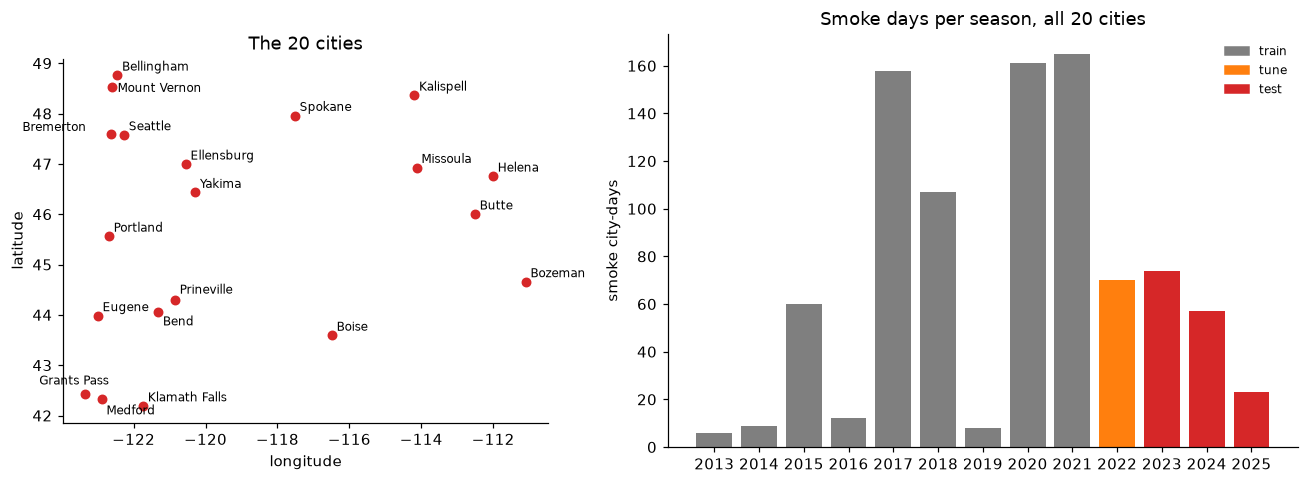

In [3]:
# Cities whose monitors only ran every third day before 2023 have no consecutive days to train on.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1, 1.3]})
ax = axes[0]
nudge = {"Bremerton": (-58, 2), "Medford": (3, -10), "Prineville": (3, 4), "Bend": (3, -9),
         "Mount Vernon": (4, -3), "Grants Pass": (-30, 6)}
ax.scatter(cities.lon, cities.lat, s=30, color="tab:red")
for _, c in cities.iterrows():
    ax.annotate(c.city, (c.lon, c.lat), fontsize=8, xytext=nudge.get(c.city, (3, 3)),
                textcoords="offset points")
ax.set_xlabel("longitude"); ax.set_ylabel("latitude"); ax.set_title("The 20 cities")
ax.set_aspect(1.4)
ax = axes[1]
tot = smoke_days.sum()
colors = ["tab:gray" if y < TUNE_YEAR else "tab:orange" if y == TUNE_YEAR else "tab:red" for y in tot.index]
ax.bar(tot.index.astype(str), tot.values, color=colors)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="tab:gray", label="train"), Patch(color="tab:orange", label="tune"),
                   Patch(color="tab:red", label="test")], fontsize=8, frameon=False)
ax.set_ylabel("smoke city-days"); ax.set_title("Smoke days per season, all 20 cities")
plt.tight_layout(); plt.savefig("figures/data_overview.png", bbox_inches="tight"); plt.show()

## 2. Features

Everything the model sees is known on the evening of day D, with one exception: tomorrow's weather. In real use that comes from a weather forecast. For training we use the weather that actually happened. Section 9 checks how much that matters.

The new idea is the regional inputs. Smoke usually reaches neighboring cities first. `reg_max` is the highest reading today within 400 km. `upwind_max` is the highest reading today among cities that lie in the direction tomorrow's wind comes from (within 600 km and ±60°).

In [4]:
NEAR_KM = 400            # "nearby" cities
UPWIND_KM = 600          # how far to look upwind
UPWIND_HALF_ANGLE = 60   # a neighbor is "upwind" if it lies within ±60° of where the wind comes from


def haversine(lat1, lon1, lat2, lon2):
    p1, p2 = np.radians(lat1), np.radians(lat2)
    a = (np.sin((p2 - p1) / 2) ** 2
         + np.cos(p1) * np.cos(p2) * np.sin(np.radians(lon2 - lon1) / 2) ** 2)
    return 6371 * 2 * np.arcsin(np.sqrt(a))


def bearing(lat1, lon1, lat2, lon2):
    """Compass direction from point 1 to point 2 (0 = north, 90 = east)."""
    p1, p2, dl = np.radians(lat1), np.radians(lat2), np.radians(lon2 - lon1)
    x = np.sin(dl) * np.cos(p2)
    y = np.cos(p1) * np.sin(p2) - np.sin(p1) * np.cos(p2) * np.cos(dl)
    return np.degrees(np.arctan2(x, y)) % 360


pairs = pd.DataFrame([
    dict(city=a.city, other=b.city, km=haversine(a.lat, a.lon, b.lat, b.lon),
         bearing=bearing(a.lat, a.lon, b.lat, b.lon))
    for _, a in cities.iterrows() for _, b in cities.iterrows() if a.city != b.city])


def add_features(df, wx="actual"):
    """One row per city and day D. Everything is known on the evening of day D,
    except tomorrow's weather, which in real use comes from a weather forecast.
    wx="actual": tomorrow's weather = what really happened (ERA5).
    wx="forecast": tomorrow's weather = the forecast issued on day D (2024-25 only)."""
    df = df.sort_values(["city", "date"]).copy()
    g = df.groupby("city")
    df["pm_today"] = df.pm25
    df["pm_yday"] = g.pm25.shift(1)
    df["pm_change"] = df.pm_today - df.pm_yday
    df["pm_max7"] = g.pm25.transform(lambda s: s.rolling(7, min_periods=3).max())
    df["target"] = g.pm25.shift(-1)                 # what we predict: PM2.5 tomorrow
    df["target_date"] = g.date.shift(-1)
    df["cams_tmrw"] = g.cams_pm25.shift(-1)         # the official CAMS forecast for tomorrow

    for c in ["wind_max", "wind_dir", "precip", "temp_max", "rh"]:
        src = c if wx == "actual" else "fc_" + c
        df[c + "_tmrw"] = g[src].shift(-1)
    rad = np.radians(df.wind_dir_tmrw)
    df["wind_from_n_tmrw"] = np.cos(rad)
    df["wind_from_e_tmrw"] = np.sin(rad)

    # Smoke in nearby cities today
    today = df[["city", "date", "pm25"]].rename(columns={"city": "other", "pm25": "pm_other"})
    near = pairs[pairs.km <= NEAR_KM].merge(today, on="other")
    reg = near.groupby(["city", "date"]).pm_other.agg(reg_mean="mean", reg_max="max")

    # Smoke today in cities upwind of tomorrow's wind
    up = (pairs[pairs.km <= UPWIND_KM].merge(today, on="other")
          .merge(df[["city", "date", "wind_dir_tmrw"]], on=["city", "date"]))
    off = (up.bearing - up.wind_dir_tmrw + 180) % 360 - 180
    upw = up[off.abs() <= UPWIND_HALF_ANGLE].groupby(["city", "date"]).pm_other.agg(
        upwind_max="max", upwind_mean="mean")

    df = df.merge(reg.reset_index(), on=["city", "date"], how="left")
    df = df.merge(upw.reset_index(), on=["city", "date"], how="left")
    df["reg_max_minus_today"] = df.reg_max - df.pm_today
    df["year"] = df.target_date.dt.year
    df["season_day"] = (df.target_date - pd.to_datetime(df.year.astype("Int64").astype(str) + "-07-01")).dt.days

    ok = (df.target.notna() & df.pm_today.notna()
          & df.target_date.dt.month.between(7, 10)
          & ((df.target_date - df.date).dt.days == 1))
    return df[ok].reset_index(drop=True)


FEATURES = [
    "pm_today", "pm_yday", "pm_change", "pm_max7",                  # this city
    "reg_mean", "reg_max", "reg_max_minus_today",                   # nearby cities today
    "upwind_max", "upwind_mean",                                    # upwind cities today
    "wind_max", "precip", "temp_max", "rh",                         # weather today
    "wind_max_tmrw", "precip_tmrw", "temp_max_tmrw", "rh_tmrw",     # weather tomorrow
    "wind_from_n_tmrw", "wind_from_e_tmrw",
    "season_day",
]
LOG_FEATURES = ["pm_today", "pm_yday", "pm_max7", "reg_mean", "reg_max", "upwind_max", "upwind_mean"]

data = add_features(raw)
print(f"{len(data):,} usable city-days (today and tomorrow both measured)")
data[["city", "date"] + FEATURES[:9] + ["target"]].sample(5, random_state=1)

22,967 usable city-days (today and tomorrow both measured)


,city,date,pm_today,pm_yday,pm_change,pm_max7,reg_mean,reg_max,reg_max_minus_today,upwind_max,upwind_mean,target
16687,Portland,2013-10-10,12.70,8.13,4.57,18.71,8.737500,11.85,-0.85,NaN,NaN,12.03
16936,Portland,2016-09-10,3.34,4.90,-1.56,4.90,5.317143,7.02,3.68,6.25,4.9225,4.82
22271,Yakima,2020-08-05,7.17,6.04,1.13,10.68,5.765714,10.01,2.84,7.54,4.9560,3.17
20091,Spokane,2014-08-13,14.12,21.14,-7.02,24.60,7.908571,20.02,5.90,10.14,4.9850,10.30
12137,Kalispell,2023-08-31,5.62,3.32,2.30,14.21,3.877500,4.50,-1.12,NaN,NaN,6.84


## 3. Train / tune / test split (by time, never shuffled)

Train on 2013-2021. Choose the warning level on 2022. Score 2023-2025 once, at the end. A smoke day is a daily average above 35 µg/m³, where EPA's "unhealthy for sensitive groups" starts.

In [5]:
train = data[data.year.isin(TRAIN_YEARS)]
tune = data[data.year == TUNE_YEAR]
test = data[data.year.isin(TEST_YEARS)]
split = pd.DataFrame({
    "years": ["2013-2021", "2022", "2023-2025"],
    "city-days": [len(train), len(tune), len(test)],
    "smoke days": [(s.target > SMOKE).sum() for s in (train, tune, test)],
    "cities": [s.city.nunique() for s in (train, tune, test)],
}, index=["train", "tune", "test"])
split

,years,city-days,smoke days,cities
train,2013-2021,13828,593,16
tune,2022,1932,66,16
test,2023-2025,7207,154,20


## 4. Baselines and models

- **Persistence:** tomorrow = today. The brief's baseline.
- **Climatology:** the average for that city and time of year in past seasons.
- **CAMS:** the official Copernicus forecast. It is a strong rival, but it had an advantage: part of the archived forecast was made after our evening decision time.
- **Ridge regression** and **gradient boosting**, trained on log PM2.5 so the worst days don't drown out everything else.

In [6]:
def climatology(history, rows):
    """Average PM2.5 for this city within ±7 days of this date, over past years."""
    out = pd.Series(np.nan, index=rows.index)
    for c, r in rows.groupby("city"):
        h = history[history.city == c]
        if len(h):
            prof = {d: np.expm1(np.log1p(h.target[(h.season_day - d).abs() <= 7]).mean())
                    for d in range(0, 123)}
            out[r.index] = r.season_day.map(prof)
    return out


def log_cols(X):
    X = X.copy()
    for c in LOG_FEATURES:
        X[c] = np.log1p(X[c].clip(lower=0))
    return X


def make_ridge():
    return make_pipeline(FunctionTransformer(log_cols),
                         SimpleImputer(strategy="median", add_indicator=True),
                         StandardScaler(), Ridge(alpha=3.0))


def make_boosting():
    return HistGradientBoostingRegressor(max_iter=400, learning_rate=0.04, max_leaf_nodes=15,
                                         min_samples_leaf=40, l2_regularization=1.0, random_state=0)


def fit(model, rows):
    # Models learn log(PM2.5): smoke values span 2 to 300+, and logs keep big days from dominating.
    return model.fit(rows[FEATURES], np.log1p(rows.target))


def predict(model, rows):
    return np.expm1(model.predict(rows[FEATURES])).clip(min=0)


def all_predictions(models, history, rows):
    p = pd.DataFrame(index=rows.index)
    p["persistence"] = rows.pm_today
    p["climatology"] = climatology(history, rows)
    p["CAMS"] = rows.cams_tmrw
    for name, m in models.items():
        p[name] = predict(m, rows)
    return p

## 5. Pick each method's warning threshold on 2022

A missed smoke day means kids running in smoke. A false alarm means an indoor practice that wasn't needed. We count a miss as three times worse. Each method gets the threshold that gives it the lowest cost on 2022, where cost = 3 × misses + false alarms.

In [7]:
def counts(actual, pred, t):
    smoke, warn = actual > SMOKE, pred > t
    return dict(hits=int((smoke & warn).sum()), misses=int((smoke & ~warn).sum()),
                false_alarms=int((~smoke & warn).sum()))


def best_threshold(actual, pred):
    """Lowest cost on the tuning year, where cost = 3 x misses + false alarms."""
    ts = np.arange(10, 60.5, 0.5)
    cost = [MISS_COST * counts(actual, pred, t)["misses"] + counts(actual, pred, t)["false_alarms"]
            for t in ts]
    return float(ts[int(np.argmin(cost))])


def score(rows, preds, thresholds):
    onset = (rows.pm_today <= SMOKE) & (rows.target > SMOKE)
    out = []
    for m in preds:
        ok = preds[m].notna()
        a, p, t = rows.target[ok], preds[m][ok], thresholds[m]
        c = counts(a, p, t)
        sm = a > SMOKE
        out.append({"method": m, "threshold": t, "days": int(ok.sum()),
                    "MAE": (a - p).abs().mean(), "MAE smoke days": (a[sm] - p[sm]).abs().mean(),
                    "smoke days": int(sm.sum()), "warned": c["hits"], "missed": c["misses"],
                    "false alarms": c["false_alarms"],
                    "onsets caught": f"{int(((p > t) & onset[ok]).sum())} of {int(onset[ok].sum())}",
                    "cost": MISS_COST * c["misses"] + c["false_alarms"]})
    return pd.DataFrame(out).set_index("method").round(1)


models = {"ridge": fit(make_ridge(), train), "boosting": fit(make_boosting(), train)}
tune_preds = all_predictions(models, train, tune)
thresholds = {m: best_threshold(tune.target[tune_preds[m].notna()], tune_preds[m].dropna())
              for m in tune_preds}
score(tune, tune_preds, thresholds)

,threshold,days,MAE,MAE smoke days,smoke days,warned,missed,false alarms,onsets caught,cost
method,,,,,,,,,,
persistence,31.0,1932,4.0,24.2,66,41,25,46,7 of 32,121
climatology,23.5,1932,5.6,46.1,66,4,62,2,1 of 32,188
CAMS,23.5,1400,5.3,26.5,65,37,28,52,15 of 31,136
ridge,28.5,1932,3.3,26.8,66,33,33,19,3 of 32,118
boosting,25.5,1932,3.3,26.3,66,40,26,35,9 of 32,113


## 6. Freeze, then score the 2023-2025 test seasons once

The final model is whichever of ridge or boosting had the lower 2022 cost. We retrain it on 2013-2022 with the same settings, keep the 2022 thresholds, and score 2023-2025.

In [8]:
# The final model is whichever of ridge / boosting had the lower cost on the 2022 tuning year.
tune_scores = score(tune, tune_preds, thresholds)
best = tune_scores.loc[["ridge", "boosting"], "cost"].idxmin()
t_best = thresholds[best]
print("final model:", best, "| warning threshold:", t_best, "µg/m³")

# Retrain on 2013-2022 with the same settings, keep the 2022 thresholds, and score 2023-2025 once.
history = data[data.year <= TUNE_YEAR]
final = {"ridge": fit(make_ridge(), history), "boosting": fit(make_boosting(), history)}
test_preds = all_predictions(final, history, test)
results = score(test, test_preds, thresholds)
results

final model: boosting | warning threshold: 25.5 µg/m³


,threshold,days,MAE,MAE smoke days,smoke days,warned,missed,false alarms,onsets caught,cost
method,,,,,,,,,,
persistence,31.0,7207,3.4,31.0,154,87,67,110,16 of 83,311
climatology,23.5,5856,4.2,47.6,79,0,79,18,0 of 46,255
CAMS,23.5,7207,4.1,38.0,154,62,92,106,23 of 83,382
ridge,28.5,7207,2.9,32.9,154,62,92,52,8 of 83,328
boosting,25.5,7207,2.8,28.9,154,99,55,134,31 of 83,299


## 7. Onset days: the day smoke first arrives

An onset day is a smoke day that follows a clean day. "Tomorrow = today" can only catch one when today was already close to 35. Below we compare methods on the same onset days, and resample whole city-seasons 2,000 times to see how sure we can be about the differences.

In [9]:
def onset_table(rows, preds, thresholds, methods):
    kind = np.where(rows.target <= SMOKE, "clean day",
                    np.where(rows.pm_today <= SMOKE, "onset (smoke arrives)", "ongoing smoke"))
    out = {}
    for m in methods:
        warn = preds[m] > thresholds[m]
        out[m] = pd.Series(warn).groupby(kind).mean().mul(100).round(0)
    t = pd.DataFrame(out)
    t.insert(0, "days", pd.Series(kind).value_counts())
    return t.loc[["onset (smoke arrives)", "ongoing smoke", "clean day"]]


MAIN = ["persistence", "CAMS", "ridge", "boosting"]
print("% of days with a warning (higher is better on smoke days, lower on clean days)")
display(onset_table(test, test_preds, thresholds, MAIN))

# Head to head on the same onset days
onsets = test[(test.pm_today <= SMOKE) & (test.target > SMOKE)].index
ours = test_preds.loc[onsets, best] > t_best
for other in ["persistence", "CAMS"]:
    theirs = test_preds.loc[onsets, other] > thresholds[other]
    print(f"{len(onsets)} onset days: {best} caught {int((ours & ~theirs).sum())} that {other} missed; "
          f"{other} caught {int((theirs & ~ours).sum())} that {best} missed")

# How sure are we? Resample whole city-seasons (a smoke event stays together) 2,000 times.
rng = np.random.default_rng(0)
blocks = test.city + " " + test.year.astype(str)
smoke = test.target > SMOKE
is_onset = smoke & (test.pm_today <= SMOKE)
per_block = pd.DataFrame({
    f"{m} {k}": v.groupby(blocks).sum()
    for m in ["persistence", "CAMS", best]
    for k, v in {"hits": (test_preds[m] > thresholds[m]) & smoke,
                 "onsets": (test_preds[m] > thresholds[m]) & is_onset,
                 "false": (test_preds[m] > thresholds[m]) & ~smoke}.items()})
draws = per_block.values[rng.integers(0, len(per_block), (2000, len(per_block)))].sum(axis=1)
draws = pd.DataFrame(draws, columns=per_block.columns)
ci = []
for other in ["persistence", "CAMS"]:
    for k in ["hits", "onsets", "false"]:
        d = draws[f"{best} {k}"] - draws[f"{other} {k}"]
        ci.append({"compared with": other, "count": {"hits": "smoke days warned", "onsets": "onsets caught",
                                                    "false": "false alarms"}[k],
                   "difference": int(per_block[f"{best} {k}"].sum() - per_block[f"{other} {k}"].sum()),
                   "95% range": f"{np.percentile(d, 2.5):+.0f} to {np.percentile(d, 97.5):+.0f}"})
pd.DataFrame(ci)

% of days with a warning (higher is better on smoke days, lower on clean days)


,days,persistence,CAMS,ridge,boosting
onset (smoke arrives),83,19.0,28.0,10.0,37.0
ongoing smoke,71,100.0,55.0,76.0,96.0
clean day,7053,2.0,2.0,1.0,2.0


83 onset days: boosting caught 17 that persistence missed; persistence caught 2 that boosting missed
83 onset days: boosting caught 21 that CAMS missed; CAMS caught 13 that boosting missed


,compared with,count,difference,95% range
0,persistence,smoke days warned,12,+5 to +19
1,persistence,onsets caught,15,+7 to +23
2,persistence,false alarms,24,-6 to +55
3,CAMS,smoke days warned,37,+10 to +68
4,CAMS,onsets caught,8,-5 to +22
5,CAMS,false alarms,28,-20 to +75


## 8. Results by city

Bend, Grants Pass, Medford and Prineville had no usable training data, so the model never saw them before the test.

In [10]:
NO_TRAINING = sorted(set(test.city) - set(history.city))
print("Cities with no training rows (the model never saw them):", NO_TRAINING)


def by_city(rows, preds, thresholds, methods):
    out = []
    for c, r in rows.groupby("city"):
        row = {"city": c, "smoke days": int((r.target > SMOKE).sum()),
               "seen in training": c not in NO_TRAINING}
        for m in methods:
            p = preds.loc[r.index, m]
            k = counts(r.target, p, thresholds[m])
            row[f"{m} warned"] = k["hits"]
            row[f"{m} false"] = k["false_alarms"]
        out.append(row)
    return pd.DataFrame(out).set_index("city").sort_values("smoke days", ascending=False)


city_table = by_city(test, test_preds, thresholds, ["persistence", "CAMS", "boosting"])
city_table

Cities with no training rows (the model never saw them): ['Bend', 'Grants Pass', 'Medford', 'Prineville']


,smoke days,seen in training,persistence warned,persistence false,CAMS warned,CAMS false,boosting warned,boosting false
city,,,,,,,,
Prineville,21,False,12,13,8,0,12,10
Grants Pass,19,False,12,11,4,1,13,8
Bend,18,False,7,16,4,0,8,11
Medford,17,False,12,7,4,2,13,9
Klamath Falls,15,True,7,14,0,0,9,15
Boise,13,True,11,5,7,7,12,16
Spokane,11,True,9,4,8,6,10,6
Yakima,8,True,4,4,6,5,5,11
Ellensburg,6,True,3,3,6,7,4,5


## 9. Honesty check: real weather forecasts instead of actual weather

The model trained on the weather that actually happened. A coach would only have the forecast. Here we swap in the forecasts that were really issued the day before (2024-2025, the only seasons available) and score again on the same days.

In [11]:
fc_data = add_features(raw, wx="forecast")
fc_test = fc_data[fc_data.year.isin([2024, 2025])]
fc_test = fc_test[fc_test[["wind_max_tmrw", "precip_tmrw"]].notna().all(axis=1)]
act_test = test[test.set_index(["city", "date"]).index.isin(fc_test.set_index(["city", "date"]).index)]

base = all_predictions({}, history, act_test)[["persistence", "CAMS"]]
rows = [score(act_test, base, thresholds).assign(**{"tomorrow's weather": "not used"})
        .pipe(lambda d: d[[d.columns[-1]] + list(d.columns[:-1])])]
for label, rws in [("actual weather (ERA5)", act_test), ("forecast issued the day before", fc_test)]:
    p = pd.DataFrame({m: predict(final[m], rws) for m in final}, index=rws.index)
    s = score(rws, p, thresholds)
    s.insert(0, "tomorrow's weather", label)
    rows.append(s)
honesty = pd.concat(rows)
honesty

,tomorrow's weather,threshold,days,MAE,MAE smoke days,smoke days,warned,missed,false alarms,onsets caught,cost
method,,,,,,,,,,,
persistence,not used,31.0,4857,3.0,22.2,80,44,36,70,11 of 47,178
CAMS,not used,23.5,4857,3.8,28.0,80,34,46,80,13 of 47,218
ridge,actual weather (ERA5),28.5,4857,2.6,26.0,80,28,52,30,5 of 47,186
boosting,actual weather (ERA5),25.5,4857,2.5,22.1,80,51,29,90,19 of 47,177
ridge,forecast issued the day before,28.5,4857,2.6,26.8,80,25,55,26,2 of 47,191
boosting,forecast issued the day before,25.5,4857,2.5,22.6,80,48,32,95,17 of 47,191


## 10. Where it fails

The two biggest missed warnings and the biggest false alarm, each from a different smoke event.

In [12]:
ev = test.assign(pred=test_preds[best], cams=test_preds["CAMS"])
missed = ev[(ev.target > SMOKE) & (ev.pred <= t_best)].assign(gap=lambda d: d.target - d.pred, kind="missed warning")
false = ev[(ev.target <= SMOKE) & (ev.pred > t_best)].assign(gap=lambda d: d.pred - d.target, kind="false alarm")


def biggest(rows, n, taken):
    """Largest errors, at most one per city per 3-week window, so each case is a different smoke event."""
    out = []
    for _, r in rows.sort_values("gap", ascending=False).iterrows():
        if all(r.city != c or abs((r.target_date - d).days) > 21 for c, d in taken):
            out.append(r); taken.append((r.city, r.target_date))
        if len(out) == n:
            break
    return out


taken = []
cases = pd.DataFrame(biggest(missed, 2, taken) + biggest(false, 1, taken))
show = cases[["kind", "city", "target_date", "pm_today", "target", "pred", "cams", "reg_max", "upwind_max",
              "wind_max_tmrw", "precip_tmrw"]].copy()
show["target_date"] = show.target_date.dt.strftime("%Y-%m-%d")
show.round(1)

,kind,city,target_date,pm_today,target,pred,cams,reg_max,upwind_max,wind_max_tmrw,precip_tmrw
13321,missed warning,Medford,2023-08-17,18.5,102.8,23.9,15.8,68.9,36.8,15.1,0.0
22647,missed warning,Yakima,2023-08-19,5.1,82.6,9.7,36.8,59.3,45.7,12.9,0.0
2301,false alarm,Boise,2024-09-06,46.9,24.8,75.2,15.6,80.9,7.6,11.5,0.0


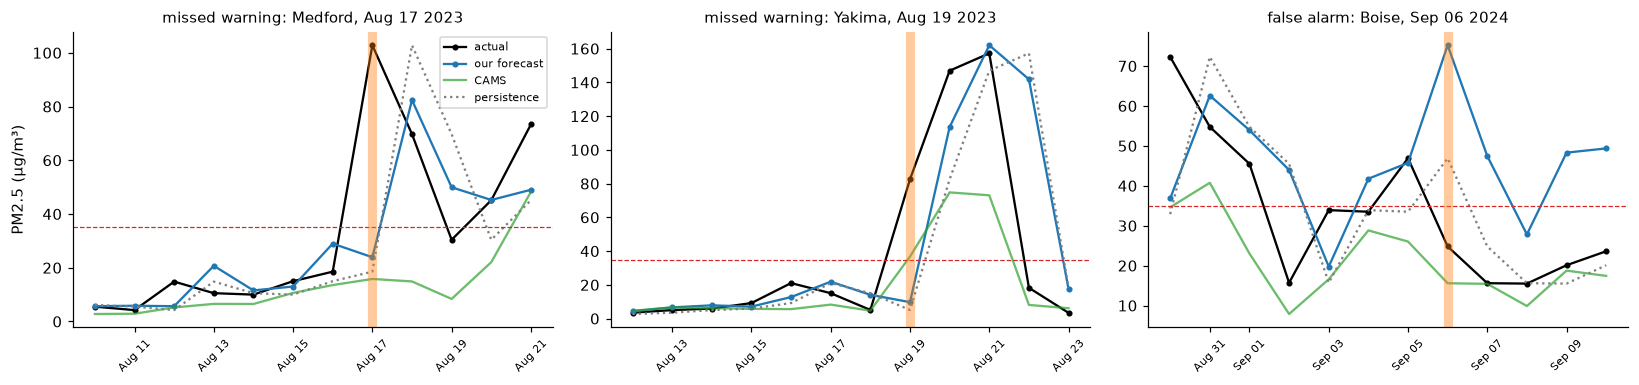

In [13]:
import matplotlib.dates as mdates


def plot_case(ax, city, day, title):
    win = ev[(ev.city == city) & (ev.target_date.between(day - pd.Timedelta(days=7), day + pd.Timedelta(days=4)))]
    ax.plot(win.target_date, win.target, "k-o", ms=3, label="actual")
    ax.plot(win.target_date, win.pred, "-o", ms=3, color="tab:blue", label="our forecast")
    ax.plot(win.target_date, win.cams, "-", color="tab:green", alpha=.7, label="CAMS")
    ax.plot(win.target_date, win.pm_today, ":", color="gray", label="persistence")
    ax.axhline(SMOKE, color="tab:red", lw=.8, ls="--")
    ax.axvline(day, color="tab:orange", alpha=.4, lw=6)
    ax.set_title(title, fontsize=10)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d")); ax.tick_params(axis="x", rotation=45, labelsize=7)


fig, axes = plt.subplots(1, len(cases), figsize=(5 * len(cases), 3.6))
for ax, (_, r) in zip(np.atleast_1d(axes), cases.iterrows()):
    plot_case(ax, r.city, r.target_date, f"{r.kind}: {r.city}, {r.target_date:%b %d %Y}")
np.atleast_1d(axes)[0].legend(fontsize=7); np.atleast_1d(axes)[0].set_ylabel("PM2.5 (µg/m³)")
plt.tight_layout(); plt.savefig("figures/failure_cases.png", bbox_inches="tight"); plt.show()

- **Medford, Aug 17 2023:** today was 19 and a nearby city was already at 69, but the forecast stayed at 24. The jump to 103 happened overnight.
- **Yakima, Aug 19 2023:** today was 5. Nearby cities were at 59 and upwind cities at 46. The model said 10. CAMS said 37 and would have warned. The actual value was 83.
- **Boise, Sep 6 2024:** today was 47 with a nearby city at 81, so the model expected more smoke (75). It cleared to 25.

## 11. A whole season

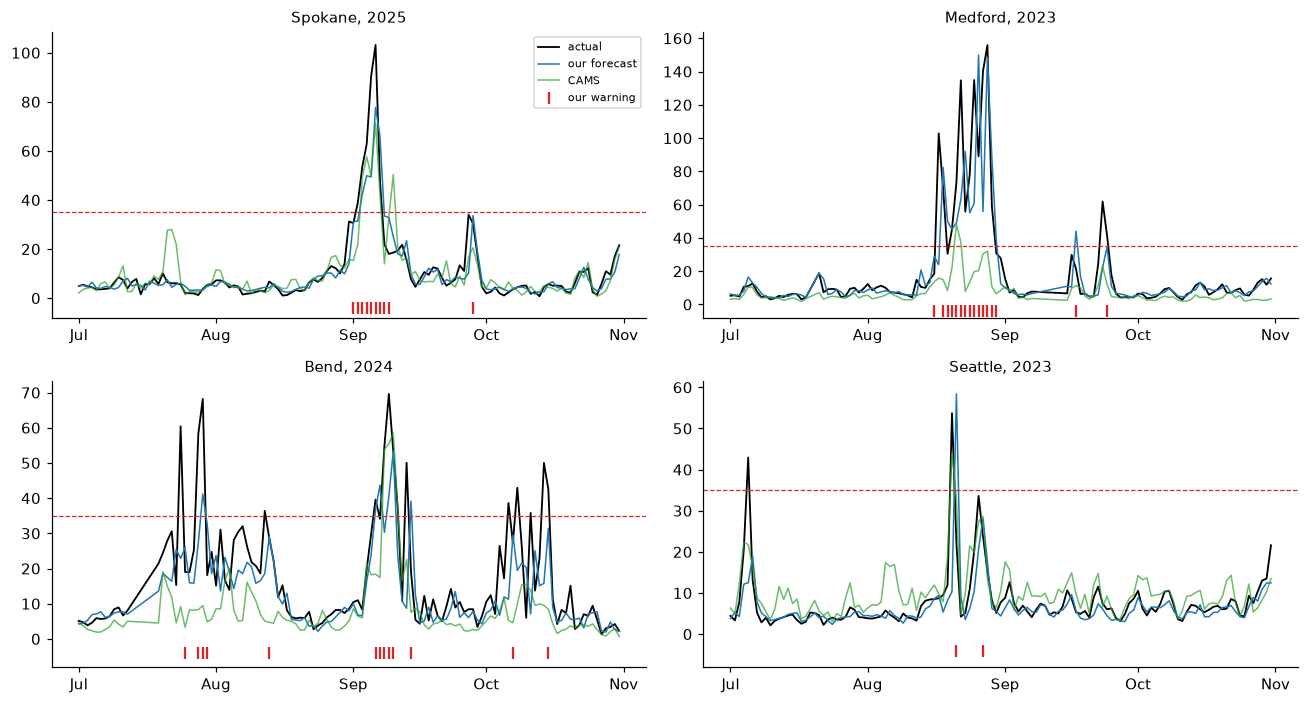

In [14]:
import matplotlib.dates as mdates


def season_plot(city, year, ax=None):
    s = ev[(ev.city == city) & (ev.year == year)]
    ax = ax or plt.gca()
    ax.plot(s.target_date, s.target, color="black", lw=1.2, label="actual")
    ax.plot(s.target_date, s.pred, color="tab:blue", lw=1, label="our forecast")
    ax.plot(s.target_date, s.cams, color="tab:green", lw=1, alpha=.7, label="CAMS")
    w = s[s.pred > t_best]
    ax.scatter(w.target_date, np.full(len(w), -4), marker="|", color="tab:red", s=60, label="our warning")
    ax.axhline(SMOKE, color="tab:red", lw=.8, ls="--")
    ax.set_title(f"{city}, {year}", fontsize=10); ax.set_ylim(bottom=-8)
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))


fig, axes = plt.subplots(2, 2, figsize=(12, 6.5))
for ax, (c, y) in zip(axes.flat, [("Spokane", 2025), ("Medford", 2023), ("Bend", 2024), ("Seattle", 2023)]):
    season_plot(c, y, ax)
axes[0, 0].legend(fontsize=7); plt.tight_layout()
plt.savefig("figures/seasons.png", bbox_inches="tight"); plt.show()

## 12. Why did it warn? A what-if explanation

For each group of inputs, we replace it with a typical fire-season value and see how much the forecast changes. The three biggest changes are listed with the decision.

In [15]:
GROUPS = {
    "smoke here today": ["pm_today", "pm_yday", "pm_change", "pm_max7"],
    "smoke in nearby cities": ["reg_mean", "reg_max", "reg_max_minus_today"],
    "smoke upwind": ["upwind_max", "upwind_mean"],
    "tomorrow's weather": ["wind_max_tmrw", "precip_tmrw", "temp_max_tmrw", "rh_tmrw",
                           "wind_from_n_tmrw", "wind_from_e_tmrw"],
    "today's weather": ["wind_max", "precip", "temp_max", "rh"],
}
TYPICAL = history[FEATURES].median()   # a typical fire-season day


def what_if(row, model):
    """How much does each group of inputs move tomorrow's forecast?
    We swap one group for its typical value and see how the forecast changes."""
    X = row[FEATURES].to_frame().T.astype(float)
    base = predict(model, X)
    effects = {}
    for g, cols in GROUPS.items():
        X2 = X.copy()
        X2[cols] = TYPICAL[cols].values
        effects[g] = float(base[0] - predict(model, X2)[0])
    return float(base[0]), effects


today_pm = raw.set_index(["city", "date"]).pm25


def detail(group, row):
    if group == "smoke here today":
        return f"{row.city} averaged {row.pm_today:.0f} µg/m³ today"
    near = pairs[(pairs.city == row.city) & (pairs.km <= NEAR_KM)]
    if group == "smoke upwind":
        near = pairs[(pairs.city == row.city) & (pairs.km <= UPWIND_KM)]
        off = (near.bearing - row.wind_dir_tmrw + 180) % 360 - 180
        near = near[off.abs() <= UPWIND_HALF_ANGLE]
    if group in ("smoke in nearby cities", "smoke upwind"):
        vals = [(today_pm.get((o, row.date), np.nan), o) for o in near.other]
        vals = [v for v in vals if not np.isnan(v[0])]
        if not vals:
            return "no nearby monitors reported"
        v, o = max(vals)
        return f"highest is {o} at {v:.0f} µg/m³"
    if group == "tomorrow's weather":
        return f"max wind {row.wind_max_tmrw:.0f} km/h, rain {row.precip_tmrw:.1f} mm"
    return f"max wind {row.wind_max:.0f} km/h, rain {row.precip:.1f} mm"


def smoke_check(city, evening):
    """The decision a coach would see on the evening of `evening`, for the next day."""
    day = pd.Timestamp(evening)
    r = ev[(ev.city == city) & (ev.date == day)]
    if r.empty:
        return f"No data for {city} on {day:%b %d %Y}. Pick a day from Jul-Oct 2023-2025."
    r = r.iloc[0]
    pred, effects = what_if(r, final[best])
    warn = pred > t_best
    top = sorted(effects.items(), key=lambda kv: -abs(kv[1]))[:3]
    lines = [f"### {city}: practice on {r.target_date:%a %b %d, %Y}",
             f"**{'MOVE PRACTICE INDOORS' if warn else 'OK TO PRACTICE OUTSIDE'}**",
             f"- Our forecast for tomorrow: **{pred:.0f} µg/m³** (we warn above {t_best:g})",
             f"- Official CAMS forecast: {r.cams_tmrw:.0f} µg/m³" if pd.notna(r.cams_tmrw) else "- Official CAMS forecast: n/a",
             f"- Persistence (tomorrow = today): {r.pm_today:.0f} µg/m³",
             "", "**What moved the forecast most:**"]
    for g, e in top:
        lines.append(f"- {g} ({detail(g, r)}): {e:+.0f} µg/m³")
    lines += ["", f"*What actually happened: {r.target:.0f} µg/m³"
              f" ({'smoke day' if r.target > SMOKE else 'not a smoke day'}).*"]
    return "\n".join(lines)


# Three example evenings from the test seasons:
# the biggest onset our model caught, the smokiest evening where it correctly said "OK tomorrow",
# and Seattle's smokiest test day.
caught = ev[(ev.pm_today <= SMOKE) & (ev.target > SMOKE) & (ev.pred > t_best)]
cleared = ev[(ev.pm_today > SMOKE) & (ev.target <= SMOKE) & (ev.pred <= t_best)]
seattle = ev[ev.city == "Seattle"]
EXAMPLE_DAYS = [(r.city, f"{r.date:%Y-%m-%d}") for r in
                [caught.nlargest(1, "target").iloc[0], cleared.nlargest(1, "pm_today").iloc[0],
                 seattle.nlargest(1, "target").iloc[0]]]
EXAMPLE_DAYS

[('Boise', '2024-07-22'),
 ('Grants Pass', '2023-08-31'),
 ('Seattle', '2023-08-19')]

In [16]:
from IPython.display import Markdown, display
for city, evening in EXAMPLE_DAYS:
    display(Markdown(smoke_check(city, evening)))

### Boise: practice on Tue Jul 23, 2024
**MOVE PRACTICE INDOORS**
- Our forecast for tomorrow: **29 µg/m³** (we warn above 25.5)
- Official CAMS forecast: 19 µg/m³
- Persistence (tomorrow = today): 17 µg/m³

**What moved the forecast most:**
- smoke here today (Boise averaged 17 µg/m³ today): +15 µg/m³
- tomorrow's weather (max wind 10 km/h, rain 0.0 mm): +15 µg/m³
- smoke upwind (highest is Kalispell at 31 µg/m³): +8 µg/m³

*What actually happened: 88 µg/m³ (smoke day).*

### Grants Pass: practice on Fri Sep 01, 2023
**OK TO PRACTICE OUTSIDE**
- Our forecast for tomorrow: **21 µg/m³** (we warn above 25.5)
- Official CAMS forecast: 9 µg/m³
- Persistence (tomorrow = today): 54 µg/m³

**What moved the forecast most:**
- smoke here today (Grants Pass averaged 54 µg/m³ today): +15 µg/m³
- today's weather (max wind 7 km/h, rain 4.6 mm): -9 µg/m³
- smoke in nearby cities (highest is Medford at 28 µg/m³): +2 µg/m³

*What actually happened: 9 µg/m³ (not a smoke day).*

### Seattle: practice on Sun Aug 20, 2023
**OK TO PRACTICE OUTSIDE**
- Our forecast for tomorrow: **10 µg/m³** (we warn above 25.5)
- Official CAMS forecast: 44 µg/m³
- Persistence (tomorrow = today): 12 µg/m³

**What moved the forecast most:**
- tomorrow's weather (max wind 19 km/h, rain 0.0 mm): +3 µg/m³
- smoke here today (Seattle averaged 12 µg/m³ today): +3 µg/m³
- smoke in nearby cities (highest is Spokane at 190 µg/m³): +1 µg/m³

*What actually happened: 54 µg/m³ (smoke day).*

## 13. Try it yourself

Pick a city and an evening from the 2023-2025 fire seasons. The demo shows tomorrow's forecast, the decision, and what moved the forecast most.

In [17]:
try:
    import gradio as gr
except ImportError:
    os.system("pip install -q gradio")
    import gradio as gr

test_days = sorted(ev.date.dt.strftime("%Y-%m-%d").unique())
with gr.Blocks(title="SmokeCheck") as demo:
    gr.Markdown("## SmokeCheck")
    with gr.Row():
        city_in = gr.Dropdown(sorted(ev.city.unique()), value="Spokane", label="City")
        day_in = gr.Dropdown(test_days, value=EXAMPLE_DAYS[0][1], label="Evening of (2023-2025 fire seasons)")
    btn = gr.Button("Check tomorrow")
    out = gr.Markdown()
    btn.click(smoke_check, [city_in, day_in], out)

if os.environ.get("SMOKECHECK_NO_LAUNCH"):
    print("Demo built (not launched in this run).")
else:
    demo.launch()

Demo built (not launched in this run).
